# 08 - Nén model (quantization) mất bao nhiêu chất lượng?

**Đo cái gì?** So cùng một model ở F16, Q8 và Q4: (1) perplexity - đo trực tiếp độ 'bối rối' của model trên văn bản mẫu, rất nhạy với nén; (2) điểm ở các notebook 01 và 03 theo từng mức nén.

**Vì sao cần?** Nén giúp model nhỏ và nhanh hơn nhưng có thể kém chính xác. Cần bằng chứng để trả lời 'Q4 có đủ tốt không?'.

**Cách đọc biểu đồ:** Mỗi đường là một model. Đường gần nằm ngang = nén gần như không mất chất lượng. Perplexity: thấp hơn là tốt hơn.

**Giới hạn (để chuẩn bị phản biện):** Chỉ model có từ 2 mức nén trở lên mới có đường. Perplexity chỉ so sánh được trong cùng một model (mỗi model có bộ từ vựng khác nhau). Cần chạy xong notebook 01 và 03 trước.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd
WIKI = st.Path('wiki.test.raw')
if not WIKI.exists():
    from datasets import load_dataset
    WIKI.write_text(''.join(load_dataset('wikitext', 'wikitext-2-raw-v1', split='test')['text']), encoding='utf-8')

C:\Users\HminhLab\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\cuda\__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
def measure(cfg):
    return {"perplexity": st.perplexity(cfg, WIKI)}      # không cần bật server


Ô này không bật server nên chạy khá nhanh.

In [3]:
st.run_all("perplexity", measure, needs_server=False, device=st.DEVICE)   # GPU mặc định, xem SLM_DEVICE

[đã có] SmolLM2-135M-Instruct (F16)
[đã có] Qwen2.5-0.5B-Instruct (F16)
[đã có] Qwen3-0.6B (F16)
[đã có] Gemma-3-1B-it (F16)
[đã có] Arch-Agent-1.5B (F16)
[đã có] xLAM-2-1B-fc-r (F16)
[đã có] Qwen3-1.7B (F16)
[đã có] Arch-Agent-3B (F16)
[đã có] Arch-Agent-1.5B (Q8)
[đã có] xLAM-2-1B-fc-r (Q8)
[đã có] Qwen3-1.7B (Q8)
[đã có] Arch-Agent-3B (Q8)
[đã có] Phi-4-mini-instruct (Q8)
[đã có] Arch-Agent-3B (Q4)
[đã có] Phi-4-mini-instruct (Q4)
[đã có] Qwen2.5-0.5B-Instruct (Q8)
[đã có] Qwen2.5-0.5B-Instruct (Q4)
[đã có] Qwen3-0.6B (Q8)
[đã có] Qwen3-0.6B (Q4)
[đã có] Gemma-3-1B-it (Q4)
[đã có] Arch-Agent-1.5B (Q4)
[đã có] xLAM-2-1B-fc-r (Q4)
[đã có] Qwen3-1.7B (Q4)


## Biểu đồ 1 - Perplexity tăng bao nhiêu khi nén?

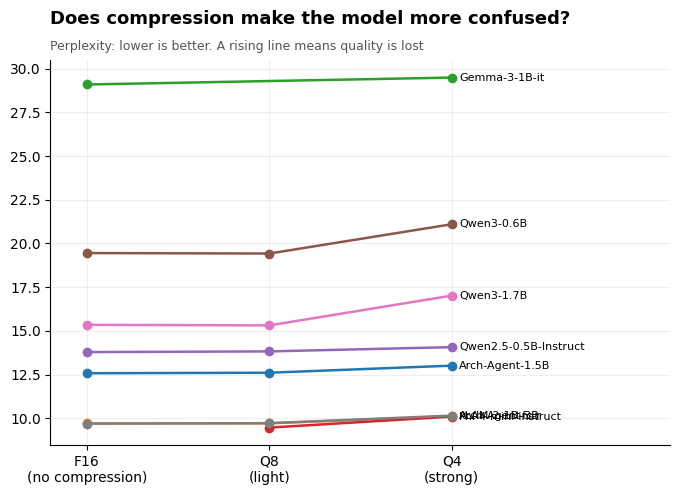

In [4]:
ppl = st.load("perplexity")
st.quant_lines(ppl, "perplexity", "Does compression make the model more confused?",
               "Perplexity: lower is better. A rising line means quality is lost", percent=False, name="08_perplexity")

## Biểu đồ 2 - Điểm chọn công cụ theo mức nén

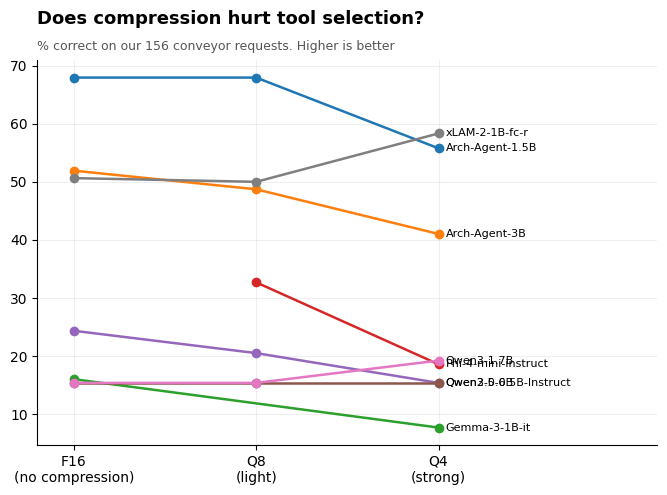

In [5]:
tool = st.load("tool_calling")
st.quant_lines(tool, "acc_all", "Does compression hurt tool selection?", "% correct on our 156 conveyor requests. Higher is better",
               name="08_tool_by_quant")

## Bảng - Mức giảm so với bản gốc F16

In [6]:
t = tool[["model", "quant", "acc_all"]].merge(ppl[["model", "quant", "perplexity"]], on=["model", "quant"], how="outer")
import os
size = pd.DataFrame([{"model": c["name"], "quant": c["quant"], "file_mb": round(os.path.getsize(c["file"]) / 2**20)}
                     for c in st.all_configs() if os.path.exists(c["file"])])
t = t.merge(size, on=["model", "quant"], how="left")
ref = t[t.quant == "F16"].set_index("model")
t["tool_score_change_pts"] = [round((r.acc_all - ref.acc_all.get(r.model, np.nan)) * 100, 1) for r in t.itertuples()]
t["perplexity_change_pct"] = [round((r.perplexity / ref.perplexity.get(r.model, np.nan) - 1) * 100, 1) for r in t.itertuples()]
t[t.model.isin(ref.index)].sort_values(["model", "quant"])

,model,quant,acc_all,perplexity,file_mb,tool_score_change_pts,perplexity_change_pct
0,Arch-Agent-1.5B,F16,0.679487,12.5761,2950,0.0,0.0
1,Arch-Agent-1.5B,Q4_K_M,0.557692,13.0109,940,-12.2,3.5
2,Arch-Agent-1.5B,Q8_0,0.679487,12.6056,1570,0.0,0.2
3,Arch-Agent-3B,F16,0.519231,9.7016,5892,0.0,0.0
4,Arch-Agent-3B,Q4_K_M,0.410256,10.1137,1840,-10.9,4.2
5,Arch-Agent-3B,Q8_0,0.487179,9.7138,3133,-3.2,0.1
6,Gemma-3-1B-it,F16,0.160256,29.0917,1914,0.0,0.0
7,Gemma-3-1B-it,Q4_K_M,0.076923,29.4873,769,-8.3,1.4
10,Qwen2.5-0.5B-Instruct,F16,0.243590,13.7863,948,0.0,0.0
11,Qwen2.5-0.5B-Instruct,Q4_K_M,0.153846,14.0695,379,-9.0,2.1
